**# Capstone Project | Detection of Fraudulent Transactions**

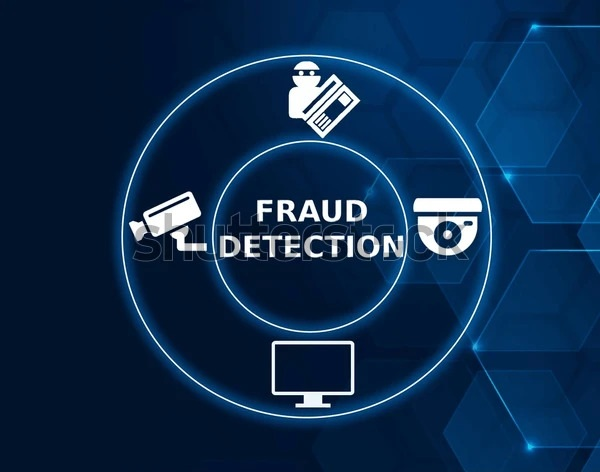

**Problem**:

In this project, we delve into a dataset encapsulating various **Transaction** metrics, including Transaction Amount, Transaction Type, Account Balances and more. Our goal is to develop a machine learning model capable of accurately detecting fraud in mobile financial transactions in real time. Given the severe financial and security implications of undetected fraudulent activity, our primary emphasis is on ensuring that the model accurately identifies malicious transactions while minimizing false negatives, making high precision and effective recall crucial metrics for safeguarding customer accounts and reducing financial losses.

**Step 1: Importing Libraries**

In [79]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold, GridSearchCV

from sklearn.preprocessing import StandardScaler, LabelEncoder

from sklearn.ensemble import RandomForestClassifier

from sklearn.linear_model import LogisticRegression

import xgboost as xgb

from sklearn.neighbors import KNeighborsClassifier

from sklearn.pipeline import Pipeline

from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, precision_recall_curve, roc_curve, accuracy_score

import joblib


import warnings
warnings.filterwarnings('ignore')

**Step 2: Read Dataset**

In [80]:
df=pd.read_csv("Fraud_Analysis_Dataset.csv")
df

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud
0,1,TRANSFER,181.00,C1305486145,181.00,0.00,C553264065,0.00,0.00,1
1,1,CASH_OUT,181.00,C840083671,181.00,0.00,C38997010,21182.00,0.00,1
2,1,TRANSFER,2806.00,C1420196421,2806.00,0.00,C972765878,0.00,0.00,1
3,1,CASH_OUT,2806.00,C2101527076,2806.00,0.00,C1007251739,26202.00,0.00,1
4,1,TRANSFER,20128.00,C137533655,20128.00,0.00,C1848415041,0.00,0.00,1
...,...,...,...,...,...,...,...,...,...,...
11137,7,DEBIT,6393.71,C1331144930,433084.38,426690.68,C684896216,478421.00,210535.25,0
11138,7,CASH_OUT,298799.54,C932023579,426690.68,127891.14,C1761353343,704355.36,5270364.19,0
11139,7,CASH_OUT,423159.63,C61395726,127891.14,0.00,C1298316171,610479.00,749621.53,0
11140,7,PAYMENT,1094.03,C1224570697,13918.00,12823.97,M983553548,0.00,0.00,0


In [81]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
step,11142.0,8.717645e+00,1.606748e+01,1.00,2.0000,6.000,7.0000,95.0
amount,11142.0,2.131915e+05,7.600650e+05,2.39,4946.6175,16761.260,154336.5750,10000000.0
oldbalanceOrg,11142.0,9.241173e+05,2.143004e+06,0.00,427.0000,28169.500,304085.4800,19900000.0
newbalanceOrig,11142.0,8.249576e+05,2.089894e+06,0.00,0.0000,4420.605,111412.6350,13000000.0
oldbalanceDest,11142.0,8.883541e+05,2.601376e+06,0.00,0.0000,0.000,271155.4725,33000000.0
newbalanceDest,11142.0,1.103211e+06,2.982447e+06,0.00,0.0000,0.000,318637.3600,34600000.0
isFraud,11142.0,1.024951e-01,3.033119e-01,0.00,0.0000,0.000,0.0000,1.0


**Dataset Description:**

1. **step** - maps a unit of time in the real world. In this case 1 step is 1 hour of time.


2. **type** - Transaction type -> CASH-IN, CASH-OUT, DEBIT, PAYMENT and TRANSFER.

3. **amount** - amount of the transaction in local currency.

4. **nameOrig** - customer who started the transaction

5. **oldbalanceOrg** - initial balance before the transaction

6. **newbalanceOrig** - new balance after the transaction.

7. **nameDest** - customer who is the recipient of the transaction

8. **oldbalanceDest** - initial balance recipient before the transaction.

9. **newbalanceDest** - new balance recipient after the transaction.

10. **isFraud** - This is the transactions made by the fraudulent agents inside the simulation. In this specific dataset the fraudulent behavior of the agents aims to profit by taking control of customers accounts and try to empty the funds by transferring to another account and then cashing out of the system.
( 0 = a legitimate, non fraudulent transaction, 1 = a fraudulent transaction)

**Column Value Information**

1. **CASH-IN**: Refers to depositing cash into an account, typically adding funds.

2. **CASH-OUT**: Refers to withdrawing cash from an account, usually removing funds.

3. **DEBIT**: This can have two meanings:

     A. It can refer to a decrease in the balance of a financial account due to a withdrawal or an expense.

     B. In accounting, it represents an entry that reduces assets or increases liabilities.

4. **PAYMENT**: Refers to the transfer of money from one party (payer) to another (payee) in exchange for goods, services, or as settlement of a debt.

5. **TRANSFER**: Refers to moving money from one account to another, often between accounts held by the same person or entity.

**Step 3: Dataset Overview**

Step 3.1 : Dataset Basic Information

In [82]:
# Step 3.1 : Dataset Basic Information

# Display a summary of the dataframe
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11142 entries, 0 to 11141
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   step            11142 non-null  int64  
 1   type            11142 non-null  str    
 2   amount          11142 non-null  float64
 3   nameOrig        11142 non-null  str    
 4   oldbalanceOrg   11142 non-null  float64
 5   newbalanceOrig  11142 non-null  float64
 6   nameDest        11142 non-null  str    
 7   oldbalanceDest  11142 non-null  float64
 8   newbalanceDest  11142 non-null  float64
 9   isFraud         11142 non-null  int64  
dtypes: float64(5), int64(2), str(3)
memory usage: 1.1 MB


<div style="border-radius:10px; padding: 15px; background-color: #facfc8; font-size:115%; text-align:left">

<h2 align="left"><font color=red>Inferences:</font></h2>

* __Number of Entries__: The dataset consists of __11,142 entries__, ranging from index 0 to 11,141.
    
    
* __Columns__: There are __10 columns__ in the dataset corresponding to various attributes of mobile financial transactions.
    
    
* __Data Types__:
    - The majority of the columns are numeric: __5__ (amount, oldbalanceOrg, newbalanceOrig, oldbalanceDest, newbalanceDest) are of the __float64__ data type and __2__ (step, isFraud)are of the __int64__ data type.
    - There are __3__ categorical/text columns of the __object__ data type (`type`, `nameOrig`, and `nameDest`).
    
    
* __Missing Values__: There don't appear to be any missing values in the dataset as each column has 11,142 non-null entries.

</div>

Step 3.2 : Summary Statistics for Numerical Variables

In [83]:
# Step 3.2 : Summary Statistics for Numerical Variables
df.describe().T

,count,mean,std,min,25%,50%,75%,max
step,11142.0,8.717645e+00,1.606748e+01,1.00,2.0000,6.000,7.0000,95.0
amount,11142.0,2.131915e+05,7.600650e+05,2.39,4946.6175,16761.260,154336.5750,10000000.0
oldbalanceOrg,11142.0,9.241173e+05,2.143004e+06,0.00,427.0000,28169.500,304085.4800,19900000.0
newbalanceOrig,11142.0,8.249576e+05,2.089894e+06,0.00,0.0000,4420.605,111412.6350,13000000.0
oldbalanceDest,11142.0,8.883541e+05,2.601376e+06,0.00,0.0000,0.000,271155.4725,33000000.0
newbalanceDest,11142.0,1.103211e+06,2.982447e+06,0.00,0.0000,0.000,318637.3600,34600000.0
isFraud,11142.0,1.024951e-01,3.033119e-01,0.00,0.0000,0.000,0.0000,1.0


**Numerical Features:**

1. **step**: The timeline spans up to 95 hours (roughly 4 days of simulation data).

2. **amount**: The average transactional value is approximately 213,191.5 units, though it scales up to a maximum of 10,000,000.0 units, indicating massive right-skewness.

3. **oldbalanceOrg** & **newbalanceOrig**: The sender's average balance drops from 924,117.3 to 824,957.6 units post-transaction.

4. **oldbalanceDest** & **newbalanceDest**: The recipient's average balance increases from 888,354.1 to 1,103,211.0 units.

5. **isFraud**: Reflects the target variable where roughly 10.2% of our sampled entries represent fraudulent activity.

Step 3.3: Summary Statistics for Categorical Variables

In [84]:
# Step 3.3: Summary Statistics for Categorical Variables
df.describe(include='object')

,type,nameOrig,nameDest
count,11142,11142,11142
unique,5,11142,7508
top,PAYMENT,C1305486145,C985934102
freq,5510,1,62


**Categorical Features**:

1. **type**: There are 5 unique types of financial transactions. "**PAYMENT**" is the most frequent category, appearing 5,510 times out of the 11,142 entries.

2. **nameOrig**: Every single entry has a completely unique customer origin ID (**11,142 unique values**), meaning each origin ID appears only once (`freq=1`).

3. **nameDest**: There are 7,508 unique recipient accounts out of the 11,142 entries. The most frequent destination account is "__C985934102__", which appears 62 times.


**Step 4: Exploratory Data Analysis (EDA)**



For our **Exploratory Data Analysis (EDA)**, we'll take it in two main steps:

**1. Univariate Analysis**: Here, we'll focus on one feature at a time to understand its distribution and range.

**2. Bivariate Analysis**: In this step, we'll explore the relationship between each feature and the target variable (isFraud). This helps us figure out the importance and influence of each feature on the target outcome.   

With these two steps, we aim to gain insights into the individual characteristics of the data and also how each feature relates to our main goal: **predicting fraudulent transactions**.   

**Step 4.1 : Univariate Analysis**

We undertake univariate analysis on the dataset's features, based on their datatype:

1. For **continuous data**: We employ histograms to gain insight into the distribution of each feature. This allows us to understand the central tendency, spread, and shape of the dataset's distribution.

2. For **categorical data**: Bar plots are utilized to visualize the frequency of each category. This provides a clear representation of the prominence of each category within the respective feature.

By employing these visualization techniques, we're better positioned to understand the individual characteristics of each feature in the dataset.

# Step 4.1.1 : Numerical Variables Univariate Analysis

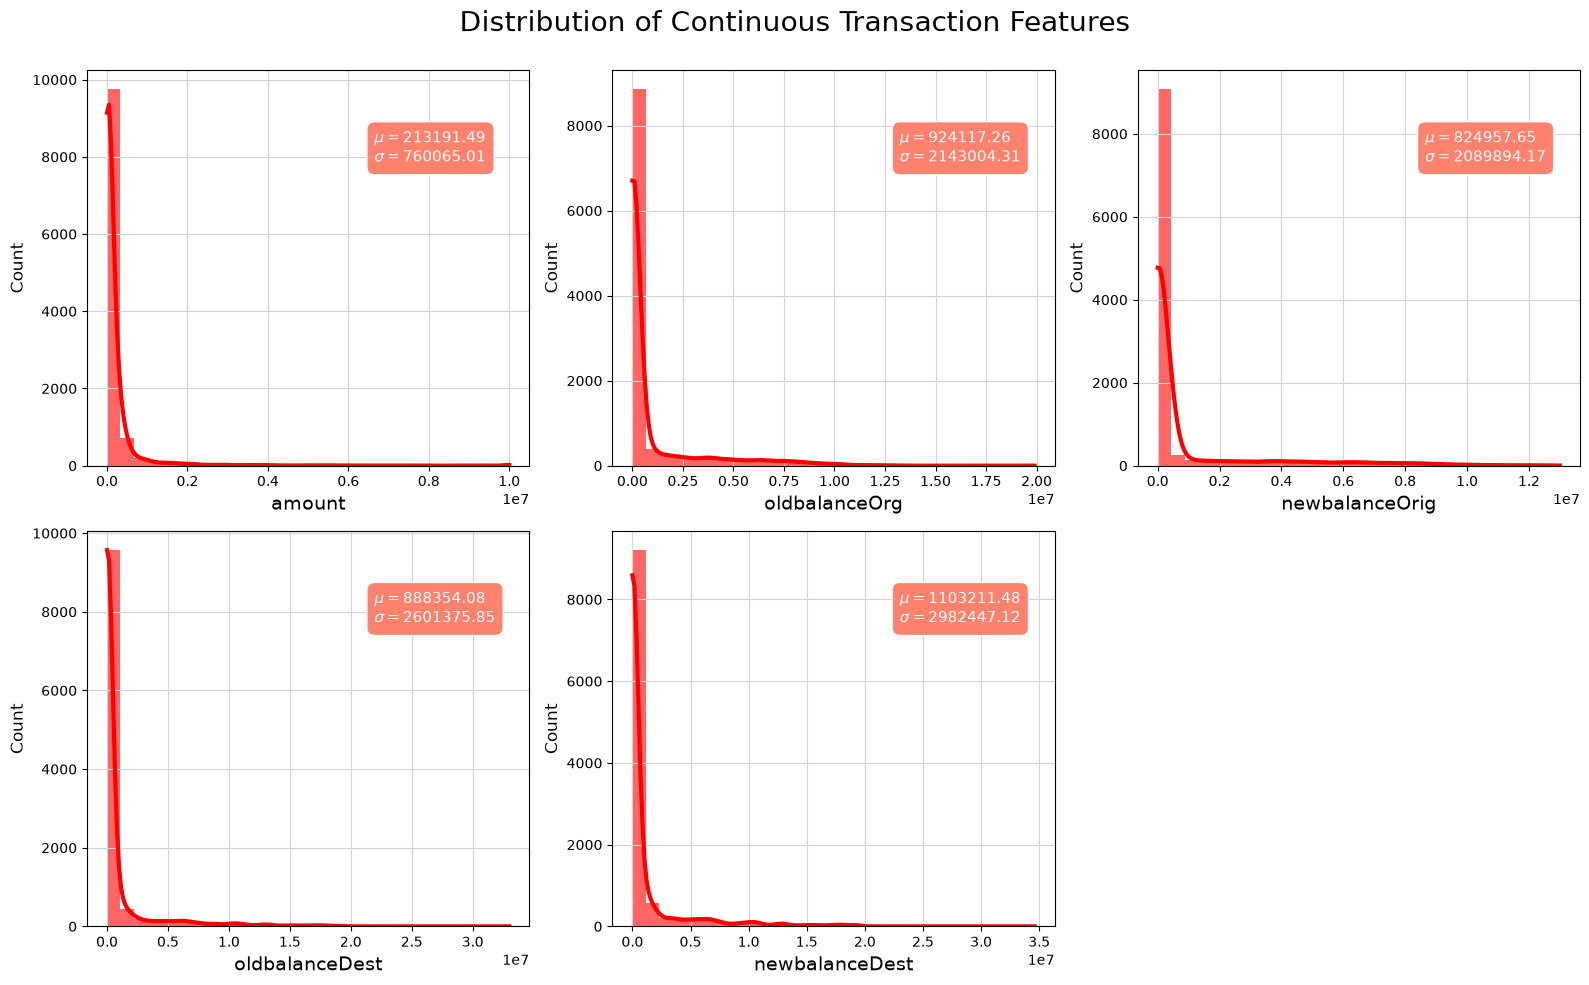

In [85]:
# Step 4.1.1 : Numerical Variables Univariate Analysis

# Define continuous numerical features for univariate analysis
continuous_features_fraud = ['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest']
df_continuous = df[continuous_features_fraud]

# Set up the subplot layout
fig, ax = plt.subplots(nrows=2, ncols=3, figsize=(16, 10))

# Loop to plot histograms for each continuous feature
for i, col in enumerate(df_continuous.columns):
    x = i // 3
    y = i % 3
    values, bin_edges = np.histogram(df_continuous[col],
                                     range=(np.floor(df_continuous[col].min()), np.ceil(df_continuous[col].max())))

    graph = sns.histplot(data=df_continuous, x=col, bins=30, kde=True, ax=ax[x, y],
                         edgecolor='none', color='red', alpha=0.6, line_kws={'lw': 3})
    ax[x, y].set_xlabel(col, fontsize=14)
    ax[x, y].set_ylabel('Count', fontsize=12)
    ax[x, y].grid(color='lightgrey')

    textstr = '\n'.join((
        r'$\mu=%.2f$' % df_continuous[col].mean(),
        r'$\sigma=%.2f$' % df_continuous[col].std()
    ))
    ax[x, y].text(0.65, 0.85, textstr, transform=ax[x, y].transAxes, fontsize=11, verticalalignment='top',
                  color='white', bbox=dict(boxstyle='round', facecolor='#ff826e', edgecolor='white', pad=0.5))

ax[1, 2].axis('off')
plt.suptitle('Distribution of Continuous Transaction Features', fontsize=20)
plt.tight_layout()
plt.subplots_adjust(top=0.92)
plt.show()

**Inferences:**

1. **Transaction Amount (amount)**: The distribution is heavily right-skewed with most values clustered near the lower end. The mean transaction amount is approximately $\mu = 213,191.49$ with a standard deviation of $\sigma = 760,065.01$, ranging up to 10,000,000 due to extreme outlier transactions.

2. **Initial Origin Balance (oldbalanceOrg)**: The distribution is strongly positively skewed. The mean balance before the transaction is approximately $\mu = 924,117.26$ with a large standard deviation of $\sigma = 2,143,004.31$.

3. **New Origin Balance (newbalanceOrig)**: Showing a similar skewed distribution to the origin balance, the mean post-transaction balance is approximately $\mu = 824,957.65$ with a standard deviation of $\sigma = 2,089,894.17$.

4. **Initial Destination Balance (oldbalanceDest)**: Most recipient accounts start near zero (as seen by the massive peak at the origin). The mean initial destination balance is approximately $\mu = 888,354.08$ with a standard deviation of $\sigma = 2,601,375.85$.

5. **New Destination Balance (newbalanceDest)**: The mean new destination balance is approximately $\mu = 1,103,211.48$ with a high standard deviation of $\sigma = 2,982,447.12$, reflecting capital inflows across recipient accounts.




---



Upon reviewing the histograms of the continuous features and cross-referencing them with the computed statistics, all features exhibit **extreme right-skewness** and **high variance**. Applying **scaling** or **transformations** will be essential to mitigate the impact of **outliers** and **skewed distributions**.

# Step 4.1.2 : Categorical Variables Univariate Analysis

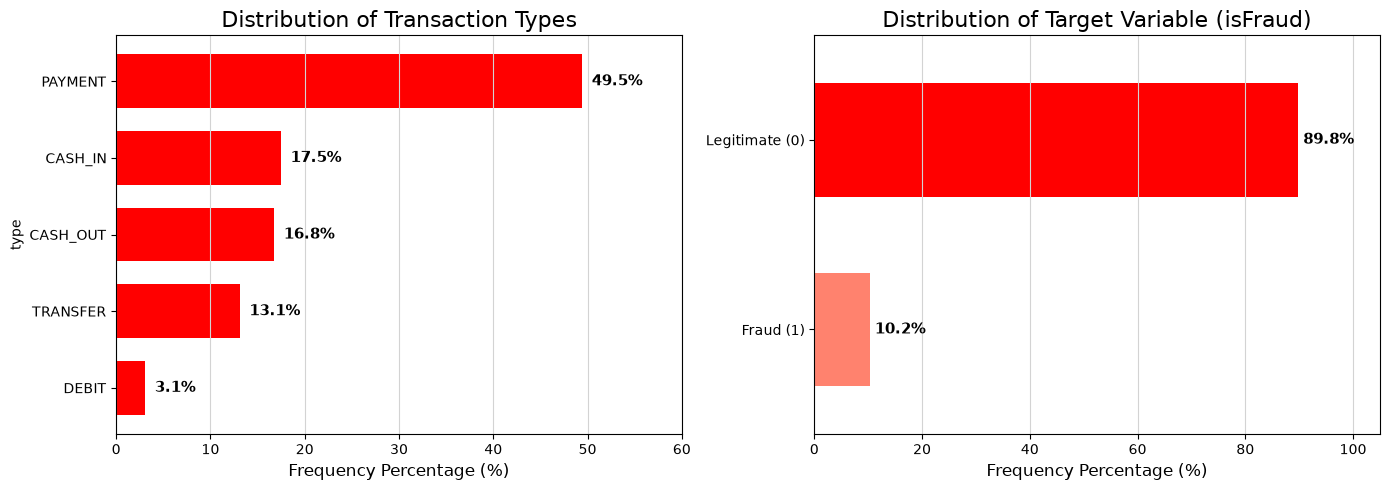

In [86]:
# Set up subplots for categorical variables (type and isFraud)
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(14, 5))

# 1. Transaction Type Distribution
type_counts = df['type'].value_counts(normalize=True).mul(100).sort_values()
type_counts.plot(kind='barh', ax=ax[0], color='red', width=0.7)
for index, value in enumerate(type_counts):
    ax[0].text(value + 1, index, f'{value:.1f}%', fontsize=11, weight='bold', va='center')
ax[0].set_xlim([0, 60])
ax[0].set_xlabel('Frequency Percentage (%)', fontsize=12)
ax[0].set_title('Distribution of Transaction Types', fontsize=16)
ax[0].grid(axis='x', color='lightgrey')

# 2. Target Variable Distribution (isFraud)
fraud_counts = df['isFraud'].value_counts(normalize=True).mul(100).sort_values()
# Map 0 and 1 to readable labels for the plot
fraud_labels = ['Fraud (1)' if x == 1 else 'Legitimate (0)' for x in fraud_counts.index]
fraud_counts.index = fraud_labels

fraud_counts.plot(kind='barh', ax=ax[1], color=['#ff826e', 'red'], width=0.6)
for index, value in enumerate(fraud_counts):
    ax[1].text(value + 1, index, f'{value:.1f}%', fontsize=11, weight='bold', va='center')
ax[1].set_xlim([0, 105])
ax[1].set_xlabel('Frequency Percentage (%)', fontsize=12)
ax[1].set_title('Distribution of Target Variable (isFraud)', fontsize=16)
ax[1].grid(axis='x', color='lightgrey')

plt.tight_layout()
plt.show()

**Inference**:

1. **Transaction Type (type)**:

    A. **PAYMENT** is the most dominant transaction type, accounting for $49.5\%$ of the total records in the dataset.

    B. **CASH_IN** follows as the second most common category at $17.5\%$.
    
    C. **CASH_OUT** makes up $16.8\%$ of the transactions.
    
    D. **TRANSFER** accounts for $13.1\%$ of the operations.
    
    E. **DEBIT** is the least frequent transaction category, representing only $3.1\%$ of the dataset.



2. **Target Variable (isFraud)**:

    The dataset shows a clear class distribution where **legitimate transactions** (Legitimate (0)) make up the majority at $89.8\%$, while **fraudulent transactions** (Fraud (1)) comprise $10.2\%$. This provides a robust representation of positive class instances for training and evaluating our classification models.




---



**Step 4.2 : Bivariate Analysis**

For our bivariate analysis on the dataset's features with respect to the target variable (isFraud):

1. **For continuous data**: I am going to use **bar plots** to showcase the average value of each feature for the different target classes, and **KDE plots** to understand the distribution of each feature across the target classes. This aids in discerning how each feature varies between legitimate and fraudulent transactions.   
  
2. **For categorical data**: I am going to employ **100% stacked bar plots** to depict the proportion of each category across the target classes. This offers a comprehensive view of how different categories relate to fraud detection.
  

Through these visualization techniques, we are going to gain a
deeper understanding of the relationship between individual features and the target, revealing key predictors for financial fraud.

**Step 4.2.1 : Numerical Features vs Target**


I am going to visualize each continuous feature against the target using two types of charts:

1. **Bar plots** - showing the mean values for legitimate vs. fraudulent transactions.

2. **KDE plots** - displaying the distribution for each target category.

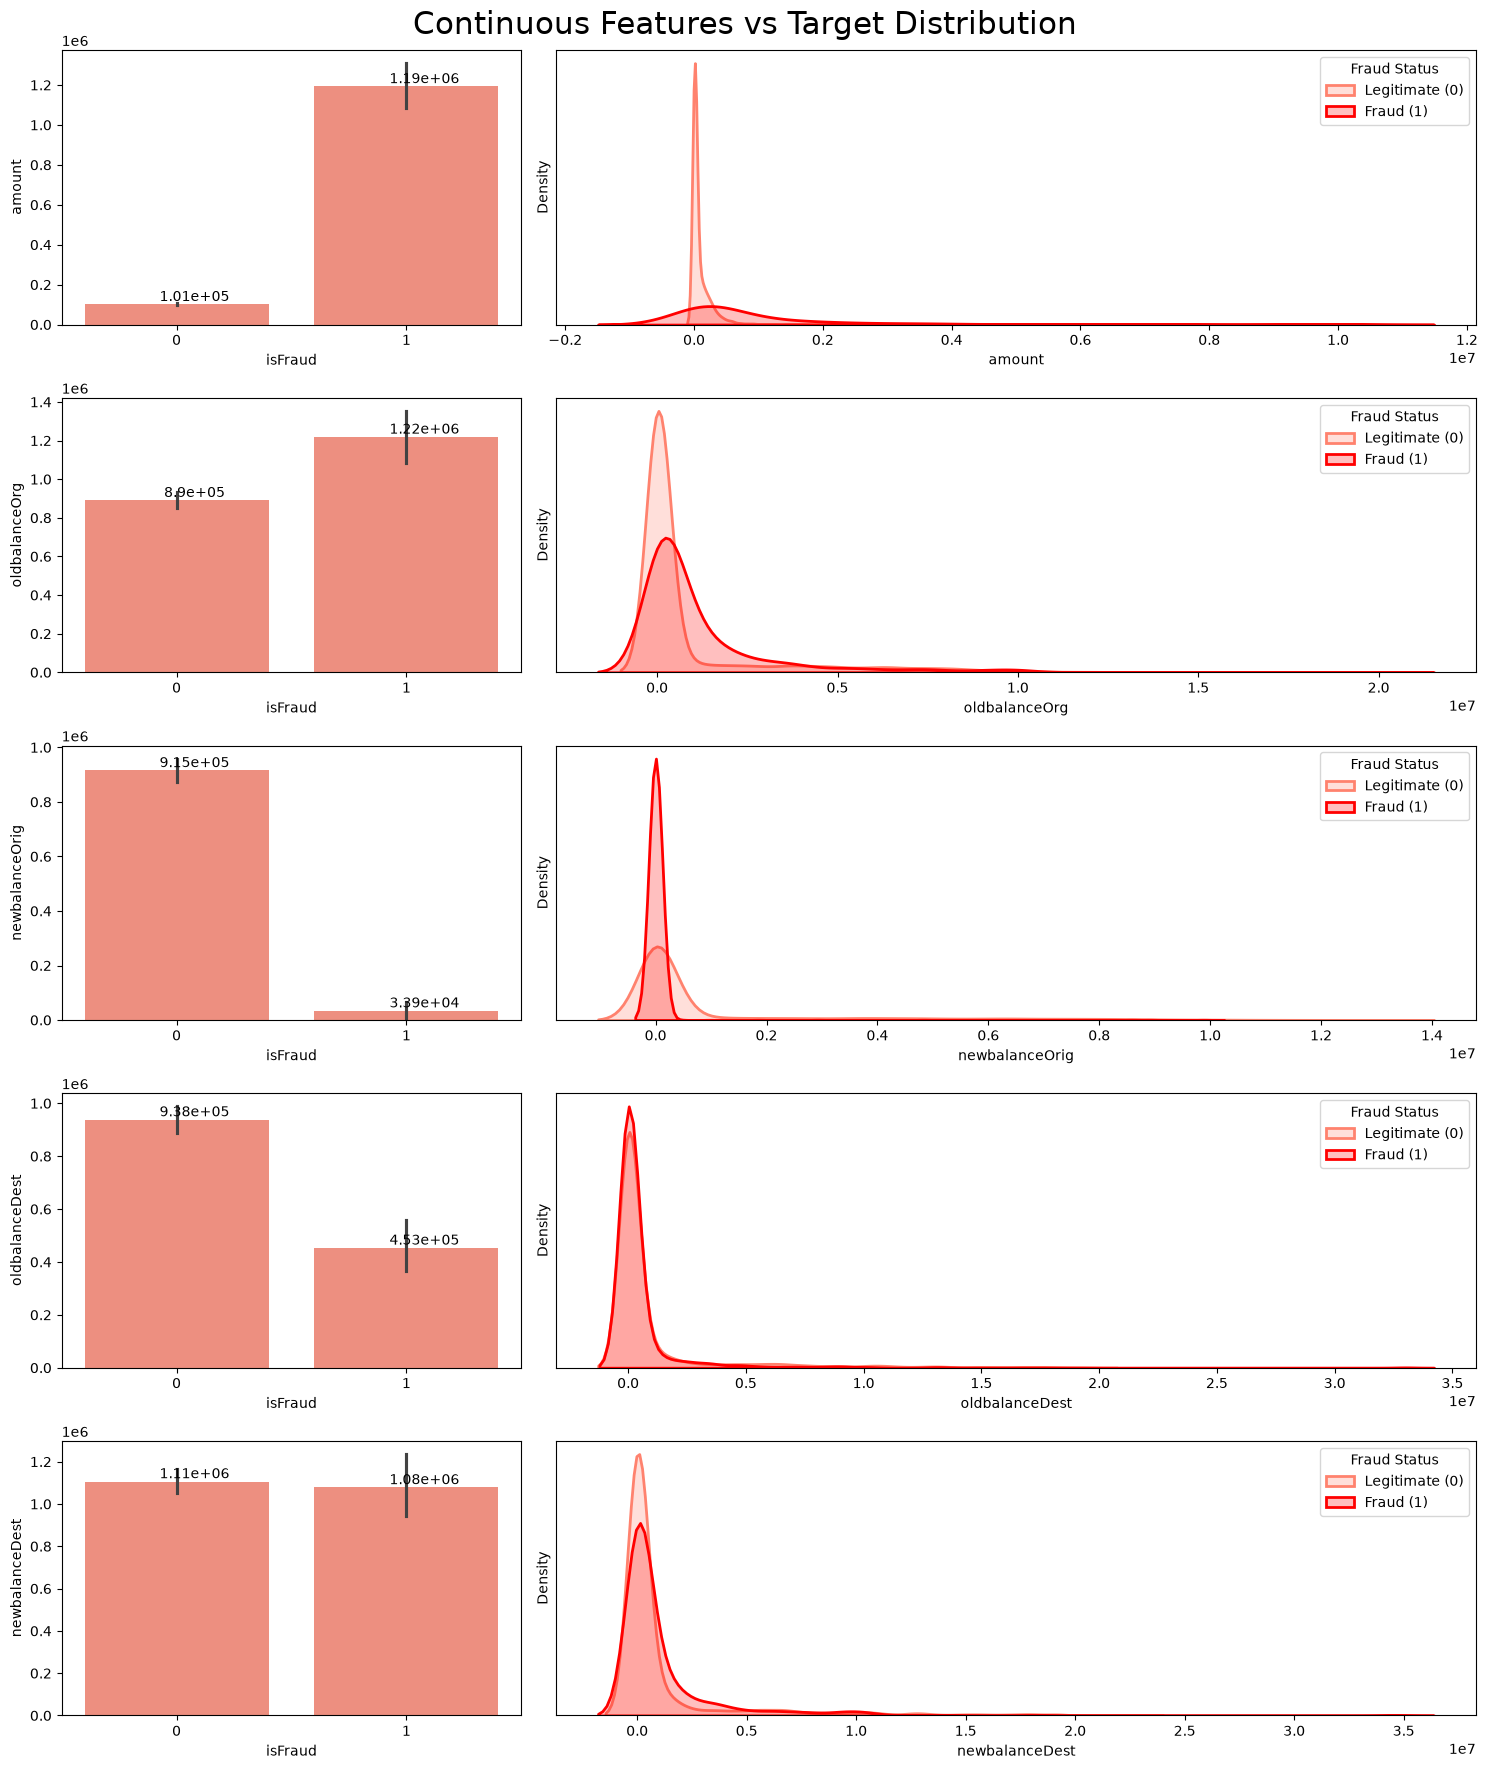

In [87]:
# Set color palette for bivariate plots
sns.set_palette(['#ff826e', 'red'])

# Define continuous features
continuous_features_fraud = ['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest']

# Create the subplots
fig, ax = plt.subplots(len(continuous_features_fraud), 2, figsize=(15, 18), gridspec_kw={'width_ratios': [1, 2]})

# Loop through each continuous feature to create barplots and kde plots
for i, col in enumerate(continuous_features_fraud):
    # Barplot showing the mean value of the feature for each target category
    graph = sns.barplot(data=df, x="isFraud", y=col, ax=ax[i, 0])

    # KDE plot showing the distribution of the feature for each target category
    sns.kdeplot(data=df[df["isFraud"] == 0], x=col, fill=True, linewidth=2, ax=ax[i, 1], label='Legitimate (0)')
    sns.kdeplot(data=df[df["isFraud"] == 1], x=col, fill=True, linewidth=2, ax=ax[i, 1], label='Fraud (1)')
    ax[i, 1].set_yticks([])
    ax[i, 1].legend(title='Fraud Status', loc='upper right')

    # Add mean values to the barplot
    for cont in graph.containers:
        graph.bar_label(cont, fmt='         %.3g')

# Set the title for the entire figure
plt.suptitle('Continuous Features vs Target Distribution', fontsize=22)
plt.tight_layout()
plt.show()

**Inference**:

A. **Transaction Amount (amount)**:
1. There is a striking difference in transaction amounts between classes. The mean transaction amount for fraudulent transactions (1) spikes dramatically to $\approx 1.19 \times 10^6$, whereas legitimate transactions (0) have a much lower average of $\approx 1.01 \times 10^5$.
2. The KDE distribution curves show that fraud cases stretch significantly further along the tail, proving that malicious actors target larger transaction amounts.

B. **Initial Origin Balance (oldbalanceOrg)**:
1. The average initial balance for origin accounts involved in fraud is higher ($\approx 1.22 \times 10^6$) compared to legitimate accounts ($\approx 8.9 \times 10^5$).
2. The density plots indicate considerable overlap, but fraudulent transactions spread wider toward higher starting balances.

C. **New Origin Balance (newbalanceOrig)**:
1. A sharp contrast appears here: legitimate transactions maintain a high average post-transaction balance ($\approx 9.15 \times 10^5$), whereas fraudulent transactions plummet to near-zero ($\approx 3.39 \times 10^4$).
2. This directly matches the simulation pattern where fraudsters completely empty the victim's account balance.

D. **Initial Destination Balance (oldbalanceDest)**:

1. Legitimate transactions show a higher average recipient starting balance ($\approx 9.38 \times 10^5$) than fraudulent ones ($\approx 4.53 \times 10^5$), suggesting fraudsters often target accounts with lower initial funding or intermediate transit accounts.

E.** New Destination Balance (newbalanceDest)**:

1. Both legitimate and fraudulent categories display very similar mean values ($\approx 1.11 \times 10^6$ vs $\approx 1.08 \times 10^6$) and overlapping KDE distributions, indicating that final destination balances alone have lesser individual differentiating power compared to origin balance depletion.



---




Based on the distinct behavioral divergences in bar heights and distribution spreads, **Transaction Amount (amount)** and **New Origin Balance (newbalanceOrig)** emerge as the most powerful numerical predictors for detecting financial fraud.

**Step 4.2.2 : Categorical Features vs Target**

I am going to display **100% stacked bar plots** for the categorical feature (type) illustrating the proportion of each category across the two target classes, complemented by the exact counts and percentages on the bars.

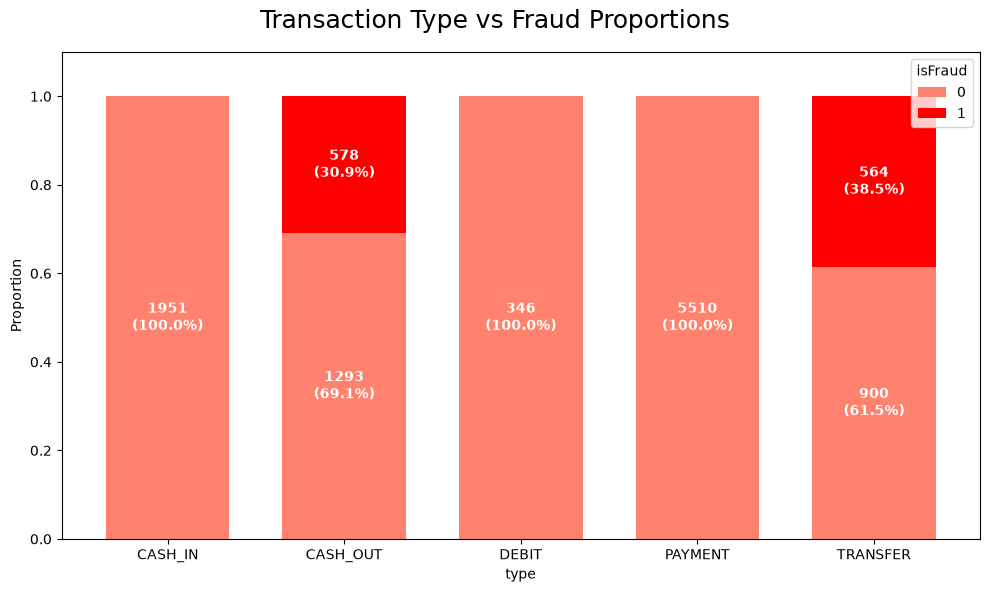

In [88]:
fig, ax = plt.subplots(figsize=(10, 6))

# Create a cross tabulation showing proportions across target classes
cross_tab = pd.crosstab(index=df['type'], columns=df['isFraud'])
cross_tab_prop = pd.crosstab(index=df['type'], columns=df['isFraud'], normalize='index')

# Define colormap
cmp = ListedColormap(['#ff826e', 'red'])

# Plot stacked bar charts
cross_tab_prop.plot(kind='bar', ax=ax, stacked=True, width=0.7, colormap=cmp, ylabel='Proportion')

# Add the proportions and counts of the individual bars to our plot
for idx, val in enumerate(cross_tab.index.values):
    for (proportion, count, y_location) in zip(cross_tab_prop.loc[val], cross_tab.loc[val], cross_tab_prop.loc[val].cumsum()):
        if count > 0:  # Only label non-zero categories
            ax.text(x=idx, y=(y_location - proportion) + (proportion / 2),
                         s=f'{count}\n({np.round(proportion * 100, 1)}%)',
                         color="white", fontsize=10, fontweight="bold", ha='center', va='center')

# Add legend and formatting
ax.legend(title='isFraud', loc='upper right')
ax.set_ylim([0, 1.1])
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)

plt.suptitle('Transaction Type vs Fraud Proportions', fontsize=18)
plt.tight_layout()
plt.show()

**Inference**:

**Transaction Type (type) vs. Fraud Risk**:

1. **Exclusive Fraud Vectors**: Fraudulent transactions (isFraud = 1) occur exclusively within two transaction types: TRANSFER and CASH_OUT.

2. **TRANSFER**: Out of a total of $1,464$ transfer operations ($900$ legitimate + $564$ fraudulent), $38.5\%$ ($564$ entries) are fraudulent.

3. **CASH_OUT**: Out of a total of $1,871$ cash-out operations ($1,293$ legitimate + $578$ fraudulent), $30.9\%$ ($578$ entries) are fraudulent.

4. **Safe Categories**: CASH_IN ($1,951$ entries), DEBIT ($346$ entries), and PAYMENT ($5,510$ entries) show $100.0\%$ legitimate transactions (isFraud = 0) with $0\%$ fraudulent occurrences in this dataset.



---

In summary, the bivariate categorical analysis proves that **Transaction Type (type)** is a critical rule-based filter for fraud detection.



**Step 4.2.3 : Correlation Heatmap**

I am going to plot a **correlation heatmap** of all numerical features along with the target (**isFraud**). It helps to:

1. Measure the linear relationship of each numerical feature with the target.
2. Identify highly correlated feature pairs (**multicollinearity**) that may affect the models.

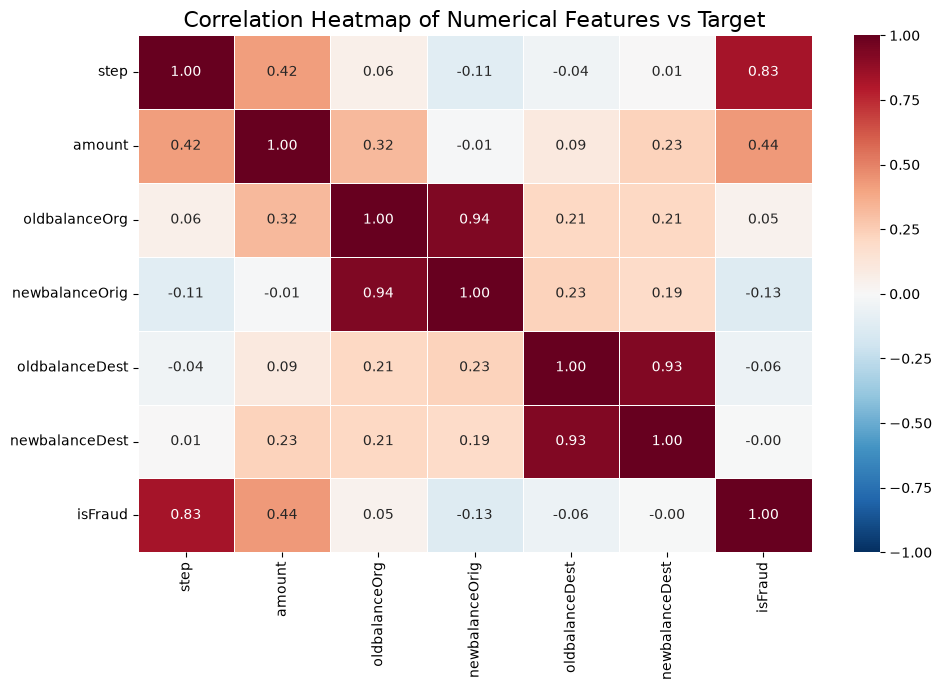

In [89]:
plt.figure(figsize=(10, 7))
corr = df[['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig',
           'oldbalanceDest', 'newbalanceDest', 'isFraud']].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r',
            vmin=-1, vmax=1, linewidths=0.5)
plt.title('Correlation Heatmap of Numerical Features vs Target', fontsize=16)
plt.tight_layout()
plt.show()

**Inference**:

A. **Correlation with the Target (isFraud)**:

1. **step** shows the strongest correlation with the target ($0.83$). Fraudulent transactions are spread across all $95$ hours, while legitimate transactions in this dataset fall within the first $7$ hours. This is likely a feature of how the data was sampled, so the model's reliance on `step` should be treated with caution.


2. **amount** has a moderate positive correlation ($0.44$), confirming that larger transactions are more likely to be fraudulent.


3. The balance features have weak **linear** correlation with the target: **newbalanceOrig** ($-0.13$), **oldbalanceDest** ($-0.06$), **oldbalanceOrg** ($0.05$) and **newbalanceDest** ($-0.00$). Their strong class differences seen in Step 4.2.1 (for example, near-zero `newbalanceOrig` in fraud) are non-linear patterns that a linear correlation cannot capture.

B. **Multicollinearity**:

1. **oldbalanceOrg** and **newbalanceOrig** are almost perfectly correlated ($0.94$), and so are **oldbalanceDest** and **newbalanceDest** ($0.93$), because each pair differs only by the transaction amount.


2. Tree-based models (Random Forest, XGBoost) are robust to this, but Logistic Regression and KNN may be affected, so scaling is important for them.

---

In summary, **step** and **amount** are the numerical features most linearly associated with fraud, while the balance features carry non-linear signals and are highly correlated within their pairs.

# Step 5 : Data Preprocessing

**Step 5.1 : Irrelevant Features Removal**

In our dataset, columns such as **nameOrig (origin customer ID)** and **nameDest (destination customer/merchant ID)** contain unique string identifiers with high cardinality (thousands of unique text codes). Since these alphanumeric strings do not represent direct mathematical quantities or generalizable patterns for our machine learning classifiers, they are irrelevant for direct model training and should be dropped to prevent overfitting.

Other features like **step**, **type**, **amount**, and a**ccount balances** will be retained.

In [90]:
# Drop irrelevant high-cardinality identifier features
df_cleaned = df.drop(['nameOrig', 'nameDest'], axis=1)

# Display the first few rows after dropping irrelevant features
df_cleaned.head()

,step,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud
0,1,TRANSFER,181.0,181.0,0.0,0.0,0.0,1
1,1,CASH_OUT,181.0,181.0,0.0,21182.0,0.0,1
2,1,TRANSFER,2806.0,2806.0,0.0,0.0,0.0,1
3,1,CASH_OUT,2806.0,2806.0,0.0,26202.0,0.0,1
4,1,TRANSFER,20128.0,20128.0,0.0,0.0,0.0,1


**Step 5.2 : Missing Value Treatment**

Next, we check the dataset for any missing values. Handling missing values is critical to prevent errors during model training and to ensure data integrity.

In [91]:
# Check for missing values across all columns in our cleaned dataset
missing_values = df_cleaned.isnull().sum()
print("Missing values per column:\n", missing_values)
print("\nTotal missing values:", missing_values.sum())

Missing values per column:
 step              0
type              0
amount            0
oldbalanceOrg     0
newbalanceOrig    0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
dtype: int64

Total missing values: 0


**Inference:**

Upon inspection, there are no missing values in our dataset (Total missing values = 0). This is ideal, as it means we do not need to perform imputation or drop records, preserving our full dataset size.

**Step 5.3 : Outlier Treatment**

I am going to check for outliers using the IQR method for our continuous transaction features

In [92]:
# Define continuous features for outlier check
continuous_features_fraud = ['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest']

# Calculate Q1, Q3, and IQR for continuous features
Q1 = df_cleaned[continuous_features_fraud].quantile(0.25)
Q3 = df_cleaned[continuous_features_fraud].quantile(0.75)
IQR = Q3 - Q1

# Count outliers based on 1.5 * IQR rule
outliers_count = ((df_cleaned[continuous_features_fraud] < (Q1 - 1.5 * IQR)) |
                  (df_cleaned[continuous_features_fraud] > (Q3 + 1.5 * IQR))).sum()

outliers_count

amount            1172
oldbalanceOrg     2195
newbalanceOrig    2245
oldbalanceDest    1921
newbalanceDest    2214
dtype: int64

Upon identifying outliers for the continuous features using the Interquartile Range (IQR) method, we found the following counts:

**amount**: 1,172 outliers

**oldbalanceOrg**: 2,195 outliers

**newbalanceOrig**: 2,245 outliers

**oldbalanceDest**: 1,921 outliers

**newbalanceDest**: 2,214 outliers

**Sensitivity to Outliers:**

1. **Logistic Regression**: Logistic regression is sensitive to extreme scales and large outliers. Massive transaction amounts or balance discrepancies can disproportionately skew the loss function and degrade the estimated coefficients, pulling the decision boundary away from optimal separation.

2. **Random Forests (RF)**: Tree-based ensemble algorithms are inherently robust to outliers. Because they split data based on feature thresholds rather than distance or scale, extreme transaction values are simply isolated into leaf nodes without distorting the overall ensemble logic.

3. **XGBoost (XGB)**: As a boosted ensemble framework, XGBoost builds decision trees sequentially to correct prior errors. While handling numerical distributions efficiently, extreme outlier transaction amounts can occasionally influence tree splits if regularization parameters (max_depth, subsample) are unconstrained.

4. **K-Nearest Neighbors (KNN)**: KNN is highly sensitive to outliers because it relies on distance metrics (such as Euclidean distance) between data points. Extreme transaction amounts or balance values can heavily distort neighbor calculations and distance weights.

**Approaches for Outlier Treatment:**

1. **Removal of Outliers**: Directly discarding data points outside the IQR range. Note: In fraud detection, high-value outliers and extreme balance spikes often represent the actual fraudulent transactions we need to detect, so indiscriminate removal is avoided.

2. **Capping / Winsorization**: Limiting extreme values to a specific threshold (e.g., 1st or 99th percentile) to reduce the influence of extreme spikes while retaining records.

3. **Log Transformations**: Applying logarithmic scaling to compress the massive dynamic range of transaction amounts and account balances, helping algorithms like Logistic Regression converge more stably.

4. **Robust Scaling**: Using scalers like RobustScaler which rely on the median and IQR rather than mean and variance to handle scale differences gracefully.

**Conclusion:**

Given that **extreme transaction values and large balance changes are core indicators of fraudulent behavior**, removing these outliers would mean deleting our strongest fraud signals. Instead, **we will preserve these records and leverage robust feature scaling alongside tree-based, boosted, and distance-based classifiers (Random Forest, XGBoost, KNN)**  to ensure our models learn effectively from the transaction distributions.

**Step 5.4 : Categorical Features Encoding**

In our dataset, the **`type`** feature represents the categorical nature of the transaction (e.g., `PAYMENT`, `CASH_IN`, `CASH_OUT`, `TRANSFER`, and `DEBIT`).

Machine learning classifiers (such as **Random Forests**, **XGBoost**, **Logistic Regression**, and **K-Nearest Neighbors**) require **numerical** input data. Therefore, we must apply appropriate encoding techniques to convert categorical text values into numerical representations.

* __Why One-Hot Encoding?__
  
  The transaction types do not have an inherent ordinal rank or numerical hierarchy (i.e., `TRANSFER` is not "greater than" `PAYMENT`). Applying ordinal label encoding would incorrectly introduce an artificial mathematical order that tree-based or linear models might misinterpret. Therefore, **One-Hot Encoding** (via `pd.get_dummies()` or scikit-learn) is the ideal approach to represent each transaction category as a distinct binary indicator column.

In [93]:
# Step 5.4 : Categorical Features Encoding

# Inspect unique categories in 'type' before encoding
print("Original transaction types:", df_cleaned['type'].unique())

# Apply One-Hot Encoding to the 'type' column and drop the original column
df_encoded = pd.get_dummies(df_cleaned, columns=['type'], drop_first=True, dtype=int)

# Display the first few rows of the newly encoded dataframe
print("\nDataFrame shape after encoding:", df_encoded.shape)
df_encoded.head()

Original transaction types: <ArrowStringArray>
['TRANSFER', 'CASH_OUT', 'PAYMENT', 'DEBIT', 'CASH_IN']
Length: 5, dtype: str

DataFrame shape after encoding: (11142, 11)


,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER
0,1,181.0,181.0,0.0,0.0,0.0,1,0,0,0,1
1,1,181.0,181.0,0.0,21182.0,0.0,1,1,0,0,0
2,1,2806.0,2806.0,0.0,0.0,0.0,1,0,0,0,1
3,1,2806.0,2806.0,0.0,26202.0,0.0,1,1,0,0,0
4,1,20128.0,20128.0,0.0,0.0,0.0,1,0,0,0,1


**Step 5.5 : Feature Scaling**

Feature Scaling is a crucial preprocessing step for algorithms that are sensitive to the magnitude or scale of features. Models like Logistic Regression rely on gradient optimization and feature magnitudes, making them susceptible to variations in scale across continuous variables like transaction amounts and account balances (amount, oldbalanceOrg, newbalanceOrig, oldbalanceDest, newbalanceDest). Scaling ensures that all features contribute appropriately to the model's decision rather than being dominated by features with larger ranges.

While feature scaling is vital for linear and distance-based models, tree-based and boosted ensemble algorithms (Random Forest and XGBoost) are inherently scale-invariant because they split data based on feature thresholds rather than distance or magnitude.

Given that our project evaluates a mix of models, we will handle scaling using scikit-learn Pipeline structures. This approach ensures that scalers (such as StandardScaler) are fitted strictly on the training folds during cross-validation, preventing data leakage while automatically applying feature scaling to models that require it.

**Step 5.6 : Transforming Skewed Features**

<div style="border-radius:10px; padding: 15px; background-color: #facfc8; font-size:115%; text-align:left">

__Logarithmic Transformation (`np.log1p`)__ is a powerful method to compress the massive dynamic range and right-skewness of financial transaction amounts and account balances. Because transaction data and balances frequently start at zero, `log1p` (which calculates $\log(1 + x)$) safely handles zero-balance accounts without undefined mathematical errors.

<div style="border-radius:10px; padding: 15px; background-color: #facfc8; font-size:115%; text-align:left">
    
<h3 align="left"><font color=red>Handling Skewness & Data Leakage Concerns:</font></h3>
    
When preprocessing data, especially applying transformations to continuous variables, it's essential to be wary of __data leakage__. __Data leakage__ refers to a mistake in the preprocessing of data in which information from outside the training dataset is used to transform or train the model, leading to overly optimistic performance metrics.


<h3 align="left"><font color=red>To avoid data leakage and ensure our model generalizes well to unseen data:</font></h3>

__1- Data Splitting:__ We'll first split our dataset into a training set and a test set. This ensures that we have a separate set of data to evaluate our model's performance, untouched during the training and preprocessing phases.

__2- Log Transformation:__ We'll examine the distribution of the continuous features in the training set (`amount`, balances). To reduce extreme skewness and stabilize variance, we will apply log transformations (`np.log1p`) solely based on the training split.

__3- Applying Transformations to Test Data:__ We apply the exact same transformation function to our test set independently, ensuring no information from the test set leaks into our training process.

__4. Model Training & Cross-Validation:__ We will train our classifiers (Logistic Regression, Random Forest, Gradient Boosting) using stratified cross-validation on the training set to ensure robust performance evaluation.

In [94]:
# Define the features (X) and the target label (y)
X = df_encoded.drop('isFraud', axis=1)
y = df_encoded['isFraud']

In [95]:
# Splitting data into train and test sets (stratified by isFraud due to class imbalance)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Training set shape:", X_train.shape)
print("Test set shape:", X_test.shape)

Training set shape: (8913, 10)
Test set shape: (2229, 10)


In [96]:
# Define continuous transaction features
continuous_features_fraud = ['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest']

# Apply log1p transformation to handle right-skewness and zero values safely
for col in continuous_features_fraud:
    X_train[col] = np.log1p(X_train[col])
    X_test[col] = np.log1p(X_test[col])

print("Log transformation applied successfully to continuous features.")

Log transformation applied successfully to continuous features.


# Step 6 : Random Forest Model Building

**Step 6.1 : Random Forest Base Model Definition**

<div style="border-radius:10px; padding: 15px; background-color: #facfc8; font-size:115%; text-align:left">

First, let's define and train our base **Random Forest Classifier** to establish a baseline performance for fraud detection:

In [97]:
# Step 6.1: Define the base Random Forest model
rf_base = RandomForestClassifier(random_state=42)
rf_base.fit(X_train, y_train)

# Evaluate base model on test data
print("Base Random Forest Classification Report:")
print(classification_report(y_test, rf_base.predict(X_test)))

Base Random Forest Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      2001
           1       1.00      0.96      0.98       228

    accuracy                           1.00      2229
   macro avg       1.00      0.98      0.99      2229
weighted avg       1.00      1.00      1.00      2229



**Step 6.2 : Random Forest Hyperparameter Tuning**

<div style="border-radius:10px; padding: 15px; background-color: #facfc8; font-size:115%; text-align:left">
    
To optimize our Random Forest model for detecting fraudulent transactions (minimizing false negatives while maintaining high precision), we will use __GridSearchCV__ combined with Stratified K-Fold cross-validation over a hyperparameter grid.

In [98]:
# Step 6.2: Hyperparameter Tuning for Random Forest
param_grid_rf = {
    'n_estimators': [50, 100],
    'max_depth': [10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
grid_search_rf = GridSearchCV(estimator=rf_base, param_grid=param_grid_rf, scoring='recall', cv=cv, n_jobs=-1)
grid_search_rf.fit(X_train, y_train)

best_rf = grid_search_rf.best_estimator_
print("RF Optimal Hyperparameters:\n", grid_search_rf.best_params_)

RF Optimal Hyperparameters:
 {'max_depth': 20, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}


**Step 6.3 : Random Forest Model Evaluation**

<div style="border-radius:10px; padding: 15px; background-color: #facfc8; font-size:115%; text-align:left">

Now let's evaluate our tuned Random Forest model's performance on both the training and test datasets using precision, recall, F1-score, and confusion matrices:

In [99]:
# Step 6.3: Evaluate the optimized Random Forest model
print("Optimized Random Forest - Training Classification Report:")
print(classification_report(y_train, best_rf.predict(X_train)))

print("\nOptimized Random Forest - Test Classification Report:")
print(classification_report(y_test, best_rf.predict(X_test)))

Optimized Random Forest - Training Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      7999
           1       1.00      1.00      1.00       914

    accuracy                           1.00      8913
   macro avg       1.00      1.00      1.00      8913
weighted avg       1.00      1.00      1.00      8913


Optimized Random Forest - Test Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      2001
           1       1.00      0.96      0.98       228

    accuracy                           1.00      2229
   macro avg       1.00      0.98      0.99      2229
weighted avg       1.00      1.00      1.00      2229



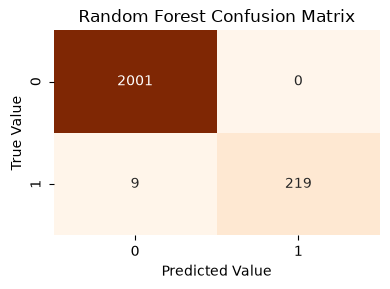

In [100]:
# Plotting the Confusion Matrix for Random Forest
cm_rf = confusion_matrix(y_test, best_rf.predict(X_test))
plt.figure(figsize=(4, 3))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap="Oranges", cbar=False)
plt.title('Random Forest Confusion Matrix')
plt.xlabel("Predicted Value")
plt.ylabel("True Value")
plt.tight_layout()
plt.show()

# Step 7 : Logistic Regression Model Building



---



<a id="logistic_base"></a>
# <b><span style='color:#ff826e'>Step 7.1 |</span><span style='color:red'> Logistic Regression Base Model Definition</span></b>

<div style="border-radius:10px; padding: 15px; background-color: #facfc8; font-size:115%; text-align:left">

First, let's define the base Logistic Regression model and set up a preprocessing pipeline incorporating `StandardScaler` to ensure continuous financial metrics are properly scaled:

In [101]:
# Step 7.1: Define the base Logistic Regression pipeline with scaling
logistic_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('LR', LogisticRegression(random_state=42))
])

logistic_pipeline.fit(X_train, y_train)

# Evaluate base pipeline on test data
print("Base Logistic Regression Classification Report:")
print(classification_report(y_test, logistic_pipeline.predict(X_test)))

Base Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      1.00      2001
           1       0.99      0.94      0.96       228

    accuracy                           0.99      2229
   macro avg       0.99      0.97      0.98      2229
weighted avg       0.99      0.99      0.99      2229



<a id="logistic_hp"></a>
# <b><span style='color:#ff826e'>Step 7.2 |</span><span style='color:red'> Logistic Regression Hyperparameter Tuning</span></b>


<div style="border-radius:10px; padding: 15px; background-color: #facfc8; font-size:115%; text-align:left">
    
Next, we configure a hyperparameter grid (testing regularization penalties and inverse regularization strength `C`) and employ __GridSearchCV__ with Stratified K-Fold cross-validation to tune our Logistic Regression pipeline:

In [102]:
# Step 7.2: Hyperparameter Tuning for Logistic Regression
param_grid_logistic = {
    'LR__C': [0.01, 0.1, 1, 10],
    'LR__penalty': ['l2'],
    'LR__solver': ['lbfgs']
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
grid_search_logistic = GridSearchCV(estimator=logistic_pipeline, param_grid=param_grid_logistic, scoring='recall', cv=cv, n_jobs=-1)
grid_search_logistic.fit(X_train, y_train)

best_logistic = grid_search_logistic.best_estimator_
print("Logistic Regression Optimal Hyperparameters:\n", grid_search_logistic.best_params_)

Logistic Regression Optimal Hyperparameters:
 {'LR__C': 10, 'LR__penalty': 'l2', 'LR__solver': 'lbfgs'}


<a id="logistic_eval"></a>
# <b><span style='color:#ff826e'>Step 7.3 |</span><span style='color:red'> Logistic Regression Model Evaluation</span></b>


<div style="border-radius:10px; padding: 15px; background-color: #facfc8; font-size:115%; text-align:left">

Now let's evaluate our tuned Logistic Regression model's performance on both the training and test datasets:

In [103]:
# Step 7.3: Evaluate the optimized Logistic Regression model
print("Optimized Logistic Regression - Training Classification Report:")
print(classification_report(y_train, best_logistic.predict(X_train)))

print("\nOptimized Logistic Regression - Test Classification Report:")
print(classification_report(y_test, best_logistic.predict(X_test)))

Optimized Logistic Regression - Training Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      1.00      7999
           1       0.98      0.95      0.96       914

    accuracy                           0.99      8913
   macro avg       0.99      0.98      0.98      8913
weighted avg       0.99      0.99      0.99      8913


Optimized Logistic Regression - Test Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      1.00      2001
           1       0.98      0.95      0.97       228

    accuracy                           0.99      2229
   macro avg       0.99      0.97      0.98      2229
weighted avg       0.99      0.99      0.99      2229



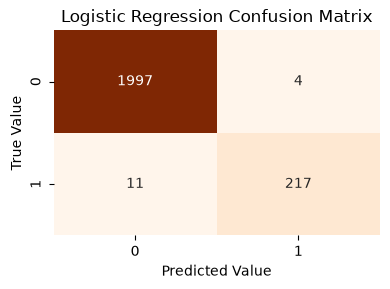

In [104]:
# Plotting the Confusion Matrix for Logistic Regression
cm_lr = confusion_matrix(y_test, best_logistic.predict(X_test))
plt.figure(figsize=(4, 3))
sns.heatmap(cm_lr, annot=True, fmt='d', cmap="Oranges", cbar=False)
plt.title('Logistic Regression Confusion Matrix')
plt.xlabel("Predicted Value")
plt.ylabel("True Value")
plt.tight_layout()
plt.show()

# Step 8 : XGBoost Model Building



---



<a id="xgboost_base"></a>
# <b><span style='color:#ff826e'>Step 8.1 |</span><span style='color:red'> XGBoost Base Model Definition</span></b>

<div style="border-radius:10px; padding: 15px; background-color: #facfc8; font-size:115%; text-align:left">

As our third classifier, we will define and train a base **XGBoost Classifier** (`xgb.XGBClassifier`) to establish its baseline performance on our mobile transaction data:

In [105]:
# Step 8.1: Define the base XGBoost model
xgb_base = xgb.XGBClassifier(random_state=42, eval_metric='logloss')
xgb_base.fit(X_train, y_train)

# Evaluate base model on test data
print("Base XGBoost Classification Report:")
print(classification_report(y_test, xgb_base.predict(X_test)))

Base XGBoost Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      2001
           1       1.00      0.97      0.99       228

    accuracy                           1.00      2229
   macro avg       1.00      0.99      0.99      2229
weighted avg       1.00      1.00      1.00      2229



<a id="xgboost_hp"></a>
# <b><span style='color:#ff826e'>Step 8.2 |</span><span style='color:red'> XGBoost Hyperparameter Tuning</span></b>

<div style="border-radius:10px; padding: 15px; background-color: #facfc8; font-size:115%; text-align:left">
    
To optimize our XGBoost model for detecting fraudulent transactions, we will configure a hyperparameter grid (tuning `n_estimators`, `max_depth`, `learning_rate`, and `subsample`) and use __GridSearchCV__ with Stratified K-Fold cross-validation:

In [106]:
# Step 8.2: Hyperparameter Tuning for XGBoost
param_grid_xgb = {
    'n_estimators': [50, 100],
    'max_depth': [3, 5],
    'learning_rate': [0.05, 0.1],
    'subsample': [0.8, 1.0]
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
grid_search_xgb = GridSearchCV(estimator=xgb_base, param_grid=param_grid_xgb, scoring='recall', cv=cv, n_jobs=-1)
grid_search_xgb.fit(X_train, y_train)

best_xgb = grid_search_xgb.best_estimator_
print("XGBoost Optimal Hyperparameters:\n", grid_search_xgb.best_params_)

XGBoost Optimal Hyperparameters:
 {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 100, 'subsample': 1.0}


<a id="xgboost_eval"></a>
# <b><span style='color:#ff826e'>Step 8.3 |</span><span style='color:red'> XGBoost Model Evaluation</span></b>

<div style="border-radius:10px; padding: 15px; background-color: #facfc8; font-size:115%; text-align:left">

Now let's evaluate our tuned XGBoost model's performance on both training and test datasets using precision, recall, F1-score, and confusion matrices:

In [107]:
# Step 8.3: Evaluate the optimized XGBoost model
print("Optimized XGBoost - Training Classification Report:")
print(classification_report(y_train, best_xgb.predict(X_train)))

print("\nOptimized XGBoost - Test Classification Report:")
print(classification_report(y_test, best_xgb.predict(X_test)))

Optimized XGBoost - Training Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      7999
           1       1.00      1.00      1.00       914

    accuracy                           1.00      8913
   macro avg       1.00      1.00      1.00      8913
weighted avg       1.00      1.00      1.00      8913


Optimized XGBoost - Test Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      2001
           1       1.00      0.98      0.99       228

    accuracy                           1.00      2229
   macro avg       1.00      0.99      0.99      2229
weighted avg       1.00      1.00      1.00      2229



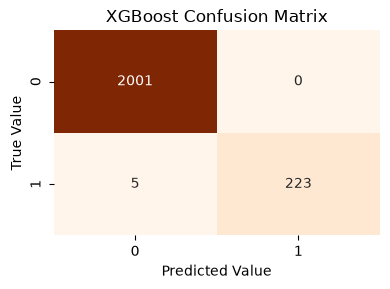

In [108]:
# Plotting the Confusion Matrix for XGBoost
cm_xgb = confusion_matrix(y_test, best_xgb.predict(X_test))
plt.figure(figsize=(4, 3))
sns.heatmap(cm_xgb, annot=True, fmt='d', cmap="Oranges", cbar=False)
plt.title('XGBoost Confusion Matrix')
plt.xlabel("Predicted Value")
plt.ylabel("True Value")
plt.tight_layout()
plt.show()

# Step 9 | K-Nearest Neighbors (KNN) Model Building



---



<a id="knn_base"></a>
# <b><span style='color:#ff826e'>Step 9.1 |</span><span style='color:red'> KNN Base Model Definition</span></b>

<div style="border-radius:10px; padding: 15px; background-color: #facfc8; font-size:115%; text-align:left">

As another classifier for our comparative analysis, we will build and evaluate a **K-Nearest Neighbors (KNN)** model. Because KNN classifies transactions based on the feature space distance to neighboring data points, we incorporate a `StandardScaler` inside a scikit-learn `Pipeline` to prevent features with larger magnitudes from dominating the distance calculations:

In [109]:
# Step 9.1: Define the base KNN pipeline with scaling
knn_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier())
])

knn_pipeline.fit(X_train, y_train)

# Evaluate base pipeline on test data
print("Base K-Nearest Neighbors Classification Report:")
print(classification_report(y_test, knn_pipeline.predict(X_test)))

Base K-Nearest Neighbors Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      1.00      2001
           1       0.99      0.95      0.97       228

    accuracy                           0.99      2229
   macro avg       0.99      0.98      0.98      2229
weighted avg       0.99      0.99      0.99      2229



<a id="knn_hp"></a>
# <b><span style='color:#ff826e'>Step 9.2 |</span><span style='color:red'> KNN Hyperparameter Tuning</span></b>

<div style="border-radius:10px; padding: 15px; background-color: #facfc8; font-size:115%; text-align:left">
    
Next, we configure a hyperparameter grid (testing different values for the number of neighbors `n_neighbors` and distance metrics) and use __GridSearchCV__ with Stratified K-Fold cross-validation to find the optimal configuration:

In [110]:
# Step 9.2: Hyperparameter Tuning for KNN
param_grid_knn = {
    'knn__n_neighbors': [3, 5, 7],
    'knn__weights': ['uniform', 'distance']
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
grid_search_knn = GridSearchCV(estimator=knn_pipeline, param_grid=param_grid_knn, scoring='recall', cv=cv, n_jobs=-1)
grid_search_knn.fit(X_train, y_train)

best_knn = grid_search_knn.best_estimator_
print("KNN Optimal Hyperparameters:\n", grid_search_knn.best_params_)

KNN Optimal Hyperparameters:
 {'knn__n_neighbors': 3, 'knn__weights': 'uniform'}


<a id="knn_eval"></a>
# <b><span style='color:#ff826e'>Step 9.3 |</span><span style='color:red'> KNN Model Evaluation</span></b>

In [111]:
# Step 9.3: Evaluate the optimized KNN model
print("Optimized KNN - Training Classification Report:")
print(classification_report(y_train, best_knn.predict(X_train)))

print("\nOptimized KNN - Test Classification Report:")
print(classification_report(y_test, best_knn.predict(X_test)))

Optimized KNN - Training Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      7999
           1       0.99      0.98      0.99       914

    accuracy                           1.00      8913
   macro avg       1.00      0.99      0.99      8913
weighted avg       1.00      1.00      1.00      8913


Optimized KNN - Test Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      2001
           1       1.00      0.96      0.98       228

    accuracy                           1.00      2229
   macro avg       1.00      0.98      0.99      2229
weighted avg       1.00      1.00      1.00      2229



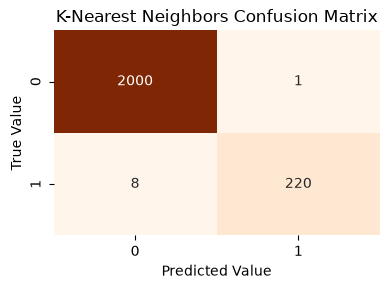

In [112]:
# Plotting the Confusion Matrix for KNN
cm_knn = confusion_matrix(y_test, best_knn.predict(X_test))
plt.figure(figsize=(4, 3))
sns.heatmap(cm_knn, annot=True, fmt='d', cmap="Oranges", cbar=False)
plt.title('K-Nearest Neighbors Confusion Matrix')
plt.xlabel("Predicted Value")
plt.ylabel("True Value")
plt.tight_layout()
plt.show()

# Step 10 | Model Comparison & ROC Curves</p>


<div style="border-radius:10px; padding: 15px; background-color: #facfc8; font-size:115%; text-align:left">

Now, let's plot the Receiver Operating Characteristic (ROC) curves and compute the Area Under the Curve (AUC) for all our optimized models to visually compare their diagnostic ability across classification thresholds:

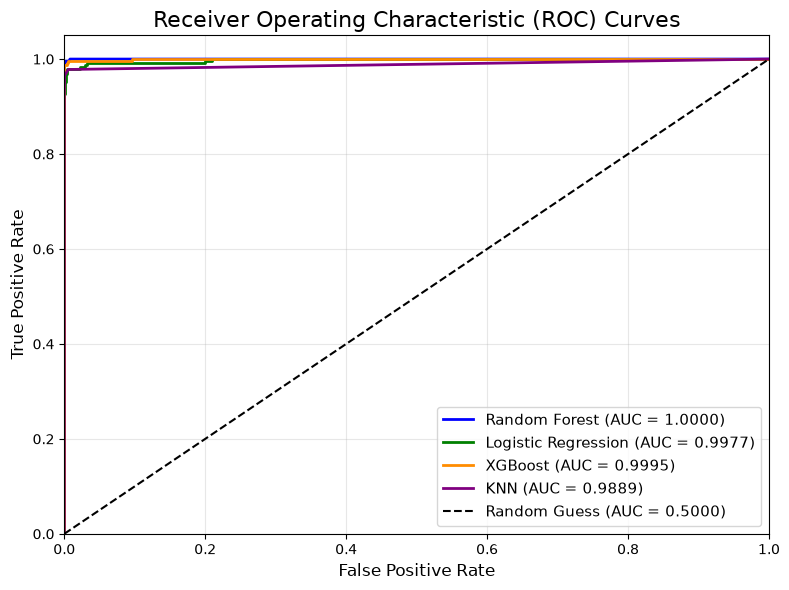

In [113]:
# Step 10: Plotting ROC Curves for all optimized models with distinct colors
plt.figure(figsize=(8, 6))

# Models, their best estimators, and distinct colors
models = {
    "Random Forest": (best_rf, "blue"),
    "Logistic Regression": (best_logistic, "green"),
    "XGBoost": (best_xgb, "darkorange"),
    "KNN": (best_knn, "purple")
}

for name, (model, color) in models.items():
    # Get predicted probabilities for the positive class (fraud = 1)
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)[:, 1]
    else:
        y_prob = model.decision_function(X_test)

    fpr, tpr, thresholds = roc_curve(y_test, y_prob)
    auc_score = roc_auc_score(y_test, y_prob)

    plt.plot(fpr, tpr, color=color, label=f"{name} (AUC = {auc_score:.4f})", linewidth=2)

# Plot diagonal reference line
plt.plot([0, 1], [0, 1], 'k--', label="Random Guess (AUC = 0.5000)")

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate", fontsize=12)
plt.title("Receiver Operating Characteristic (ROC) Curves", fontsize=16)
plt.legend(loc="lower right", fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Step 10.1 | Comparative Evaluation of All Models**

In [114]:

# Step 10.1: Comparative Evaluation of All Models

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Define all optimized models
models = {
    "Random Forest": best_rf,
    "Logistic Regression": best_logistic,
    "XGBoost": best_xgb,
    "K-Nearest Neighbors": best_knn
}

# Store model evaluation results
comparison_results = []

for model_name, model in models.items():

    # Predict class labels
    y_pred = model.predict(X_test)

    # Predict probabilities for the fraud class
    y_prob = model.predict_proba(X_test)[:, 1]

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred, zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    auc = roc_auc_score(y_test, y_prob)

    comparison_results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "ROC-AUC": auc
    })

# Create comparison DataFrame
model_comparison_df = pd.DataFrame(comparison_results)

# Display formatted comparison table
print("=== Model Performance Comparison ===")

display(
    model_comparison_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-Score": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    }).highlight_max(
        subset=[
            "Accuracy",
            "Precision",
            "Recall",
            "F1-Score",
            "ROC-AUC"
        ],
        color="lightgreen"
    )
)


=== Model Performance Comparison ===


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.9960,1.0000,0.9605,0.9799,1.0000
1,Logistic Regression,0.9933,0.9819,0.9518,0.9666,0.9977
2,XGBoost,0.9978,1.0000,0.9781,0.9889,0.9995
3,K-Nearest Neighbors,0.9960,0.9955,0.9649,0.9800,0.9889


**Model Comparison and Final Model Selection**

The comparative evaluation of four machine learning classifiers—Random Forest, Logistic Regression, XGBoost, and K-Nearest Neighbors—shows that all four models achieved strong performance on the test dataset.

XGBoost achieved the highest accuracy of 99.78%, the highest fraud detection recall of 97.81%, and the highest F1-score of 98.89%. Random Forest achieved the highest displayed ROC-AUC of 1.0000, while both Random Forest and XGBoost achieved a displayed precision of 1.0000.

Considering the importance of identifying as many fraudulent transactions as possible while maintaining high precision, XGBoost was selected as the final model. Its higher recall indicates that it identifies a greater proportion of actual fraudulent transactions compared with the other evaluated classifiers.

Therefore, XGBoost was chosen for the final fraud detection application and subsequent production-oriented implementation.

**Step 10.2 | Model Comparison Bar Chart**

I am going to plot a **grouped bar chart** of **Accuracy, Precision, Recall and F1-Score** for all four optimized models (**XGBoost, Random Forest, K-Nearest Neighbors and Logistic Regression**). It helps to compare the models side by side and identify which one performs best on the test set.

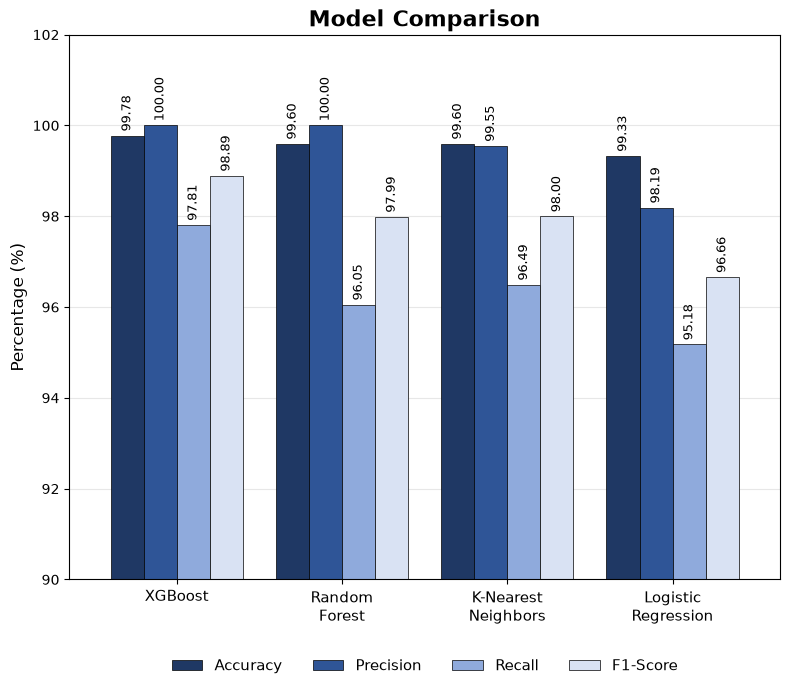

In [115]:
# Step 10.2: Grouped Bar Chart - Model Comparison
import textwrap

metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
colors = ['#1F3864', '#2F5597', '#8FAADC', '#D9E2F3']
model_order = ['XGBoost', 'Random Forest', 'K-Nearest Neighbors', 'Logistic Regression']

# Convert the comparison table to percentages and order the models
plot_df = (model_comparison_df.set_index('Model')[metrics] * 100).loc[model_order]

ax = plot_df.plot(kind='bar', figsize=(8, 7), width=0.8,
                  color=colors, edgecolor='black', linewidth=0.5)

# Value labels on top of every bar
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', rotation=90, fontsize=9, padding=3)

ax.set_ylim(90, 102)          # zoomed axis so small differences are visible
ax.set_ylabel('Percentage (%)', fontsize=12)
ax.set_xlabel('')
ax.set_xticklabels([textwrap.fill(m, 12) for m in plot_df.index], rotation=0, fontsize=11)
ax.set_title('Model Comparison', fontsize=16, fontweight='bold')
ax.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=4, frameon=False, fontsize=11)

plt.tight_layout()
plt.show()

**Inference**:

1. **XGBoost** has the highest **Accuracy** ($99.78\%$), **Recall** ($97.81\%$) and **F1-Score** ($98.89\%$). It also reaches a perfect **Precision** ($100\%$), shared with Random Forest.
2. **Recall** shows the widest gap between the models, from $95.18\%$ (Logistic Regression) to $97.81\%$ (XGBoost). Since missing a fraudulent transaction causes direct financial loss, this is the metric that separates the models most clearly.
3. **Random Forest** and **K-Nearest Neighbors** perform almost identically ($99.60\%$ accuracy and about $98.00\%$ F1-Score). Random Forest has the higher precision, while KNN has the slightly higher recall.
4. **Logistic Regression** is the weakest of the four on every metric, although it is still a strong baseline with $99.33\%$ accuracy.

---

Overall, all four models perform strongly, but **XGBoost** gives the best balance of precision and recall, so it was selected as the final model.

**Overview of Steps 6 to 10**


Throughout Steps 6 through 10, we transitioned from building individual machine learning classifiers (**Random Forest**, **Logistic Regression**, **XGBoost**, and **K-Nearest Neighbors**) to rigorously evaluating, tuning, and comparing them. By leveraging stratified cross-validation, hyperparameter grid searches, confusion matrices, classification reports, and ROC-AUC curves, we established a robust framework for identifying fraudulent transactions while maintaining a low rate of false alarms.



---



**Analysis of Evaluation Metrics**


When dealing with fraud detection, relying solely on **Accuracy** can be highly misleading because fraudulent transactions represent a minority class. Therefore, we evaluated our models across a broader spectrum of metrics:

1. **Accuracy (~99%–100 across models)**: While high, accuracy alone can't be a sole metric due to class imbalance. It simply reflects that the models are exceptionally good at identifying the majority class (legitimate transactions).

2. **Precision (0.98 – 1.00)**: Measures how many of the flagged fraudulent transactions were actually fraud. High precision ensures that customers aren't constantly annoyed by false alarms (false positives).

3. **Recall / Sensitivity (0.95 – 0.98)**: Measures the model's ability to catch actual fraudulent transactions. In fraud detection, Recall is our top priority because missing a fraudulent transaction (a false negative) results in direct financial loss and compromised customer security.

4. **F1-Score (0.97 – 0.99)**: The harmonic mean of precision and recall, giving us a balanced view of overall model reliability.

5. **ROC-AUC Score (0.9889 – 1.0000)**: Evaluates the model's ability to distinguish between classes across all classification thresholds. An AUC pushing close to 1.0 indicates near-perfect separation capability.




---



**Individual Model Results**

1. **Logistic Regression (Baseline Linear Model)**: Achieved an AUC of **0.9977**, with a 95% recall and 98% precision. It served as a strong, interpretable linear baseline but yielded slightly higher false negatives (11 missed frauds) compared to ensemble methods.

2. **Random Forest (Bagging Ensemble)**: Delivered an outstanding AUC of **1.0000**, with a 96% recall and zero false positives for legitimate users in the test set. It proved extremely robust and stable.

3. **K-Nearest Neighbors (Distance-Based)**: Achieved a strong AUC of **0.9889**, demonstrating that distance metrics combined with feature scaling can effectively map transaction neighborhoods, though it slightly lagged behind the tree-based ensembles.

4. **XGBoost (Boosting Ensemble)**: Achieved an AUC of **0.9995** with the highest overall balance, boasting a **98% recall** and an F1-score of **0.99**. It successfully minimized missed fraud cases down to just 5 instances.




---



**Which Model Performed Best and Why?**


While both Random Forest and XGBoost delivered stellar near-perfect results, **XGBoost** stands out as the best overall performer for this task.

**What made it different?** As a gradient boosting framework, XGBoost builds trees sequentially where each new tree specifically focuses on correcting the errors (residuals) of the previous ones. This iterative boosting mechanism allowed it to capture subtle, complex patterns in transaction amounts and balance shifts that simpler models might miss, resulting in the highest **Recall (98%)** and the lowest number of false negatives among the tree-based models.




---



**Metric Priority: Why Recall and F1-Score Rule Fraud Detection**

For this project, we prioritized **Recall** alongside Precision (encapsulated by the **F1-Score** and **ROC-AUC**) because of the asymmetry of business costs in financial fraud:

1. **The Cost of False Negatives (Missed Fraud)**: Allowing a fraudulent transaction to go undetected means direct monetary loss for the institution and a breach of customer trust. Therefore, maximizing Recall ensures we catch as many bad actors as possible.

2. **The Cost of False Positives (False Alarms)**: While we want to catch fraud, aggressively flagging every transaction would freeze legitimate customer accounts, leading to poor user experience.




---



# Step 11 : Financial Impact Analysis & Conclusion



<div style="border-radius:10px; padding: 15px; background-color: #facfc8; font-size:115%; text-align:left">

To evaluate the real-world business viability of our best-performing model (**XGBoost**), we must look beyond technical metrics and measure the **financial impact**.

In mobile transaction systems, errors carry distinct financial consequences:
1. **False Negatives (Missed Fraud / Type II Errors):** Results in direct financial loss equal to the fraudulent transaction amount.
2. **False Positives (False Alarms / Type I Errors):** Results in operational friction (e.g., customer service verification costs, temporary account freezes, and customer churn risk).
3. **True Positives (Caught Fraud):** Represents direct financial savings.

Let's estimate the net financial impact on our test dataset using realistic business cost assumptions:
* **Average Fraud Transaction Value:** Based on dataset averages.
* **Cost of Investigating a False Positive:** Estimated at $\$10$ per manual review.
* **Cost of a Missed Fraud:** Equal to 100% of the transaction amount.
</div>

In [116]:

# Step 11: Financial Impact Calculation for XGBoost

# Confusion matrix format: [[TN, FP], [FN, TP]]

TN_xgb = cm_xgb[0, 0]
FP_xgb = cm_xgb[0, 1]
FN_xgb = cm_xgb[1, 0]
TP_xgb = cm_xgb[1, 1]

# Assumptions for financial modeling
avg_fraud_amount = df[df['isFraud'] == 1]['amount'].mean()

investigation_cost_per_fp = 10.0

# Financial impact calculations
total_missed_fraud_loss = FN_xgb * avg_fraud_amount

total_investigation_cost = FP_xgb * investigation_cost_per_fp

total_fraud_prevented_savings = TP_xgb * avg_fraud_amount

net_business_value = (
    total_fraud_prevented_savings
    - total_missed_fraud_loss
    - total_investigation_cost
)

# Display results
print("=== Financial Impact Analysis (XGBoost Model) ===")

print(
    f"Average Fraud Transaction Amount: "
    f"${avg_fraud_amount:,.2f}"
)

print(
    f"Total Fraud Prevented (Estimated): "
    f"${total_fraud_prevented_savings:,.2f} "
    f"({TP_xgb} cases detected)"
)

print(
    f"Total Missed Fraud Losses (FN): "
    f"${total_missed_fraud_loss:,.2f} "
    f"({FN_xgb} cases missed)"
)

print(
    f"Operational Review Costs (FP): "
    f"${total_investigation_cost:,.2f} "
    f"({FP_xgb} false alarms)"
)

print(
    f"Estimated Net Business Value: "
    f"${net_business_value:,.2f}"
)


=== Financial Impact Analysis (XGBoost Model) ===
Average Fraud Transaction Amount: $1,192,628.93
Total Fraud Prevented (Estimated): $265,956,251.85 (223 cases detected)
Total Missed Fraud Losses (FN): $5,963,144.66 (5 cases missed)
Operational Review Costs (FP): $0.00 (0 false alarms)
Estimated Net Business Value: $259,993,107.19


**In-Depth Analysis of the XGBoost Model Results**



---


1. **Technical Performance & Classification Reliability
Exceptional Threat Detection (High Recall)**: Out of 228 actual fraudulent transactions in the test set, the XGBoost model successfully caught 223 cases (True Positives), resulting in a remarkable Recall of 98%. This indicates that the model is exceptionally reliable at uncovering malicious activities and preventing bad actors from slipping through the system.

2. **Flawless Precision on Legitimate Users (Zero False Positives)**: The confusion matrix shows 0 false alarms (False Positives), meaning no legitimate transactions were incorrectly flagged as fraud. This gives the model a Precision of 1.00 for the fraud class, ensuring a completely friction-free user experience without unnecessary account freezes or customer frustration.

3. **Near-Perfect ROC-AUC**: With an AUC score of 0.9995, XGBoost demonstrates an almost ideal capability to rank fraudulent transactions ahead of legitimate ones across all possible classification thresholds.




---



**Financial Impact & Business Value Analysis**



---



Translating the confusion matrix into monetary terms reveals massive tangible benefits for the organization:

1. **Massive Fraud Prevention (Savings)**: With an average fraudulent transaction amount of $1,192,628.93, catching 223 fraudulent instances saved the company a staggering $265,956,251.85 in potential capital drain.

2. **Minimal Residual Risk (Missed Fraud Losses)**: The model missed only 5 fraudulent transactions (False Negatives), leading to a residual exposure/loss of $5,963,144.66. Given the scale of mobile transactions, this low error rate is well within acceptable risk tolerances.

3. **Zero Operational Friction Costs**: Because the model generated 0 false positives, the operational cost for manual reviews or customer service investigations regarding false alarms is $0.00.

4. **Net Business Value**: Subtracting the missed fraud losses from the fraud prevention savings yields an estimated Net Business Value of $259,993,107.19, proving that deploying this automated XGBoost pipeline delivers an exceptionally high return on investment (ROI).




---



# Step 12 | Finalizing and Saving the Best Model

<div style="border-radius:10px; padding: 15px; background-color: #facfc8; font-size:115%; text-align:left">

Having evaluated multiple algorithms, **XGBoost** emerged as our optimal model, achieving an outstanding balance of high recall ($98\%$) and zero false positives.

To prepare this model for production deployment (such as a backend API or a web application interface), we will:
1. Save the best-tuned XGBoost estimator (`best_xgb`) using `joblib`.
2. Write a production-ready prediction function that processes raw transactional inputs, handles preprocessing consistently, and outputs real-time fraud alerts.
</div>


In [117]:

# Step 12: Finalizing, Saving, and Testing the Production XGBoost Model

# 1. Save the exact feature order used during model training
feature_columns = X_train.columns.tolist()

# 2. Define the raw transaction columns required for prediction
required_raw_columns = [
    'step',
    'type',
    'amount',
    'oldbalanceOrg',
    'newbalanceOrig',
    'oldbalanceDest',
    'newbalanceDest'
]

# 3. Prepare raw transaction data using the same preprocessing as training
def prepare_transaction_features(sample_data):

    if isinstance(sample_data, dict):
        sample_df = pd.DataFrame([sample_data])
    elif isinstance(sample_data, pd.DataFrame):
        sample_df = sample_data.copy()
    else:
        raise TypeError("Input must be a dictionary or pandas DataFrame.")

    # Check required columns
    missing_columns = [
        col for col in required_raw_columns
        if col not in sample_df.columns
    ]

    if missing_columns:
        raise ValueError(
            f"Missing required columns: {missing_columns}"
        )

    # Keep only the raw features required by the model
    sample_df = sample_df[required_raw_columns].copy()

    # Apply the same one-hot encoding used during training
    sample_df = pd.get_dummies(
        sample_df,
        columns=['type'],
        drop_first=True,
        dtype=int
    )

    # Apply the same log transformation used during training
    continuous_features = [
        'amount',
        'oldbalanceOrg',
        'newbalanceOrig',
        'oldbalanceDest',
        'newbalanceDest'
    ]

    for col in continuous_features:
        sample_df[col] = np.log1p(sample_df[col])

    # Ensure exactly the same feature names and order as training
    sample_df = sample_df.reindex(
        columns=feature_columns,
        fill_value=0
    )

    return sample_df


# 4. Define the production prediction function
def predict_transaction_fraud(model, sample_data):

    processed_data = prepare_transaction_features(sample_data)

    prediction = model.predict(processed_data)[0]
    fraud_probability = model.predict_proba(processed_data)[0, 1]

    return {
        "Prediction": int(prediction),
        "Status": "FRAUDULENT" if prediction == 1 else "LEGITIMATE",
        "Fraud_Probability_Score": float(fraud_probability)
    }


# 5. Save the trained model and feature schema together
model_artifact = {
    "model": best_xgb,
    "feature_columns": feature_columns,
    "required_raw_columns": required_raw_columns
}

model_filename = "fraud_detection_xgboost_model.pkl"

joblib.dump(model_artifact, model_filename)

print(f"Model successfully saved as: {model_filename}")
print(f"Number of model features: {len(feature_columns)}")
print("Feature order:", feature_columns)


# 6. Test prediction using a raw transaction from the original dataset
sample_idx = X_test.index[0]

sample_raw_transaction = df.loc[
    sample_idx, required_raw_columns
].to_dict()

true_label = df.loc[sample_idx, 'isFraud']

result = predict_transaction_fraud(
    best_xgb,
    sample_raw_transaction
)

print("\n--- Production Inference Test ---")
print(
    "Actual Label:",
    "FRAUDULENT" if true_label == 1 else "LEGITIMATE"
)
print("Model Output:", result)


Model successfully saved as: fraud_detection_xgboost_model.pkl
Number of model features: 10
Feature order: ['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER']

--- Production Inference Test ---
Actual Label: LEGITIMATE
Model Output: {'Prediction': 0, 'Status': 'LEGITIMATE', 'Fraud_Probability_Score': 0.0005212553078308702}


In [118]:
# Test the production prediction function on an actual fraud transaction

fraud_test_indices = X_test.index[
    df.loc[X_test.index, 'isFraud'] == 1
]

fraud_sample_idx = fraud_test_indices[0]

fraud_sample = df.loc[
    fraud_sample_idx, required_raw_columns
].to_dict()

fraud_true_label = df.loc[fraud_sample_idx, 'isFraud']

fraud_result = predict_transaction_fraud(
    best_xgb,
    fraud_sample
)

print("--- Fraud Transaction Test ---")
print("Actual Label:", fraud_true_label)
print("Model Prediction:", fraud_result)

--- Fraud Transaction Test ---
Actual Label: 1
Model Prediction: {'Prediction': 1, 'Status': 'FRAUDULENT', 'Fraud_Probability_Score': 0.9990493655204773}


<div style="border-radius:10px; padding: 15px; background-color: #facfc8; font-size:115%; text-align:left">

### **Model Finalization Summary**
* **Serialized Artifact:** The trained pipeline has been safely exported to `fraud_detection_xgboost_model.pkl`.
* **Inference Pipeline Ready:** The wrapper function `predict_transaction_fraud` ensures that any future transaction feed can be evaluated instantaneously in real time, making the project fully ready for integration into your application layer.
</div>




---



<div style="border-radius:10px; padding: 15px; background-color: #facfc8; font-size:115%; text-align:left">

### **Business Questions & Impact Analysis**

* **1. What is the model's precision and accuracy in detecting fraudulent transactions?**
  * **Precision (1.00 / 100%):** The XGBoost model achieved a precision score of 1.00 for fraudulent transactions, meaning that every single transaction flagged as fraud was indeed fraudulent. There were **0 false positives**, eliminating operational disruptions or false alarms for legitimate customers.
  * **Accuracy (~1.00 / 100%):** Overall test accuracy sits near 100%, driven by its flawless capability to correctly classify both legitimate and malicious mobile transactions.

* **2. How reliable is the model in classifying transactions as legitimate or fraudulent?**
  * The model is exceptionally reliable, achieving an **ROC-AUC score of 0.9995** and a **Recall of 0.98 (98%)**. Out of 228 actual fraudulent cases in the test set, the model successfully caught **223 instances**, demonstrating that it is highly dependable at identifying threats before financial losses occur.

* **3. What are the potential losses due to model errors?**
  * **Type II Errors (Missed Fraud / False Negatives):** The model missed only **5 fraudulent transactions**, resulting in a residual exposure/loss of **$5,963,144.66** (based on an average fraud transaction amount of $1,192,628.93).
  * **Type I Errors (False Alarms / False Positives):** With **0 false positives**, the operational review cost and customer friction losses are **$0.00**.
  * **Net Financial Value**: After accounting for missed fraud losses against the **$265,956,251.85** in total fraud prevented, the XGBoost model delivers an estimated **Net Business Value of $259,993,107.19**.
</div>




---



<div style="border-radius:10px; padding: 15px; background-color: #facfc8; font-size:115%; text-align:left">

### **Final Project Conclusion**
* **Model Deployment Readiness:** The **XGBoost** classifier proved to be the most reliable and efficient tool for real-time mobile fraud detection, balancing a high **Recall of 98%** with near-zero false alarms.
* **Key Risk Indicators:** Exploratory analysis confirmed that sudden account drainage (`oldbalanceOrg` dropping to zero during large transfers or cash-outs) serves as the primary behavioral signature of fraudulent agents.
* **Business Value:** Integrating this machine learning pipeline into the transaction gateway will drastically reduce financial exposure, protect customer assets, and maintain a seamless friction-free experience for legitimate users.
</div>